In [29]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100); pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110

# ---------------- CONFIG: edit these ----------------
SOURCE = "snapshot/snapshot.parquet"   # raw/snapshot file, cleaned on the fly by clean_data.load_and_clean
USE_SAVED = False                      # True: read cleaned/clients_clean.parquet and cleaned/transactions_clean.parquet
SAVED_DIR = "cleaned"
PLOT_SAMPLE = 1_000_000                # max transaction rows used for histograms
MIN_N = 30                             # minimum group size shown in rate tables
RANDOM_STATE = 0

### Loading Data

In [2]:
if USE_SAVED:
    clients = pd.read_parquet(f"{SAVED_DIR}/clients_clean.parquet")
    txns = pd.read_parquet(f"{SAVED_DIR}/transactions_clean.parquet")
    report = None
else:
    from clean_data import load_and_clean
    clients, txns, report = load_and_clean(SOURCE)

ID, OBS, M0, TARGET, PAY = "cifwithcheckdigit", "obs_id", "m0_monthenddate", "target_value", "payment_date"
TXN_DATE, TXN_TYPE, AMT, BAL, SPEND, CAT = "transactiondate", "trantypedesc", "amount", "balance", "spendgroup", "categoryname"
KEY = [ID, OBS] if OBS in clients.columns else [ID, M0]
for c in (M0, PAY):
    if c in clients: clients[c] = pd.to_datetime(clients[c])
clients[ID] = clients[ID].astype(str)

print(f"Observation key: {KEY}")
print(f"clients: {clients.shape}  |  txns: {txns.shape}")
print(f"memory: clients {clients.memory_usage(deep=True).sum()/1e6:,.1f} MB | txns {txns.memory_usage(deep=True).sum()/1e6:,.1f} MB")
display(clients.dtypes.to_frame("clients dtype").join(txns.dtypes.to_frame("txns dtype"), how="outer"))

Observation key: ['cifwithcheckdigit', 'obs_id']
Observation-level columns (16): ['obs_seq', 'm0_monthenddate', 'm0_arrearsamount', 'crccreditlimit', 'due_count', 'payment_count', 'm0_total_due_with_arrears', 'total_paid', 'target_value', 'target_rule', 'new_to_arrears_flag', 'product_group', 'm0_start_cd_group', 'payment_date', 'collectionsmethodname', 'exclude_flag']
Transaction-level columns (8): ['days_from_payment', 'tx_period', 'transactiondate', 'trantypedesc', 'amount', 'balance', 'spendgroup', 'categoryname']
Ignored when matching duplicates (row counters): []
Building clients table ...
  4,482,046 raw rows -> 10,499 observations (4,999 customers) (2s)
Building transactions table ...
  transactions batch 1/1: 3,534,387 rows kept (3s)
CLIENTS (one row per observation)                                             
  raw rows (observation fields repeated per transaction)             4,482,046
  observations after cleaning                                           10,499
  distinct

,clients dtype,txns dtype
amount,NaN,float64
amount_slog,NaN,float32
arrears_share_of_due,float32,NaN
balance,NaN,float64
balance_slog,NaN,float32
categoryname,NaN,category
cifwithcheckdigit,str,category
collectionsmethodname,category,NaN
crccreditlimit,float64,NaN
crccreditlimit_slog,float32,NaN


### Aggregate data

In [8]:
keys = ["cifwithcheckdigit", "obs_id"]

txn_features = (
    txns.groupby(keys)
    .agg(
        n_txn=("amount", "size"),
        #inflow_sum=("inflow", "sum"),
        #outflow_sum=("outflow", "sum"),
        bal_mean=("balance", "mean"),
        bal_min=("balance", "min"),
        bal_std=("balance", "std"),
    )
    .reset_index()
)
"""

txn_features["net_flow"] = (
    txn_features["inflow_sum"] - txn_features["outflow_sum"]
)

txn_features["outflow_to_inflow"] = (
    txn_features["outflow_sum"]
    / txn_features["inflow_sum"].replace(0, np.nan)
)
"""

df = clients.merge(
    txn_features,
    on=keys,
    how="left",
    validate="one_to_one"
)

df["n_txn"] = df["n_txn"].fillna(0)

## kNN Pipeline

In [15]:
numeric_features = [
    "n_txn",
    #"inflow_sum",
    #"outflow_sum",
    #"net_flow",
    #"outflow_to_inflow",
    #"bal_last",
    "bal_mean",
    "bal_min",
    "bal_std",
    #"pct_neg_bal",
    #"pct_zero_bal",
    #"days_since_last_txn",
    #"history_days",
    "m0_arrearsamount",
    "m0_arrearsamount_slog",
    "m0_total_due_with_arrears",
    "m0_total_due_with_arrears_slog",
    "arrears_share_of_due",
    "crccreditlimit",
    "crccreditlimit_slog",
    "days_payment_before_m0"
]


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median",
                              add_indicator=True)),
    ("scaler", RobustScaler()),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
])

knn = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(
        n_neighbors=15,
        weights="distance",
        metric="minkowski",
        p=2,
        n_jobs=-1,
    )),
])

In [17]:
target = "target_value"

# Exclude identifiers, targets, and outcome-derived fields
exclude = [
    "cifwithcheckdigit",
    "obs_id",
    "target_value",
    "target_rule",
    "payment_count",
    "total_paid",
    "total_paid_slog"
]

feature_cols = [
    c for c in df.select_dtypes(include="number").columns
    if c not in exclude
]

X = df[feature_cols]
y = df[target]
groups = df["cifwithcheckdigit"]

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# X: engineered features
# y: target_value
# groups: client identifier

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df["cifwithcheckdigit"])
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

Balanced accuracy: 0.6748029448509391
Macro F1: 0.6744295818200694
              precision    recall  f1-score   support

           0       0.66      0.69      0.67      1007
           1       0.69      0.66      0.67      1054

    accuracy                           0.67      2061
   macro avg       0.67      0.67      0.67      2061
weighted avg       0.68      0.67      0.67      2061



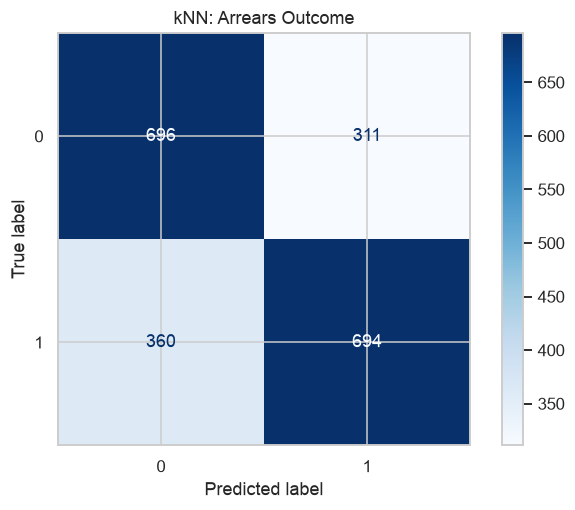

In [20]:

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    f1_score,
)
import matplotlib.pyplot as plt

knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print("Balanced accuracy:",
      balanced_accuracy_score(y_test, y_pred))
print("Macro F1:",
      f1_score(y_test, y_pred, average="macro"))
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues"
)
plt.title("kNN: Arrears Outcome")
plt.tight_layout()
plt.show()


## Testing clusters

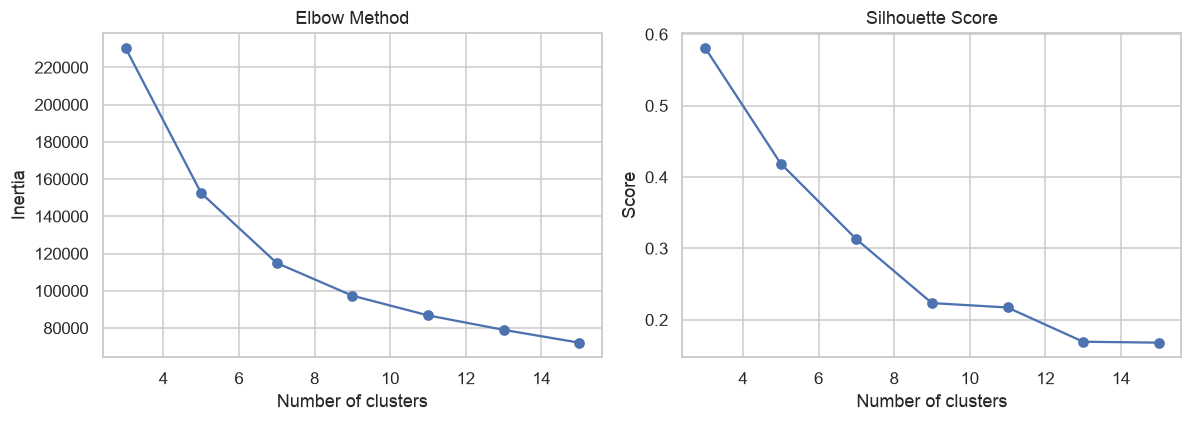

In [45]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt

# Fit preprocessing to the feature data for exploratory clustering
X_scaled = preprocessor.fit_transform(X)

# Compare possible numbers of clusters
results = []

for k in range(3, 16, 2):
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(
            X_scaled, labels,
            sample_size=min(10000, len(X)),
            random_state=RANDOM_STATE
        )
    })

results = pd.DataFrame(results)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(results["k"], results["inertia"], marker="o")
axes[0].set(title="Elbow Method",
            xlabel="Number of clusters", ylabel="Inertia")

axes[1].plot(results["k"], results["silhouette"], marker="o")
axes[1].set(title="Silhouette Score",
            xlabel="Number of clusters", ylabel="Score")

plt.tight_layout()
plt.show()


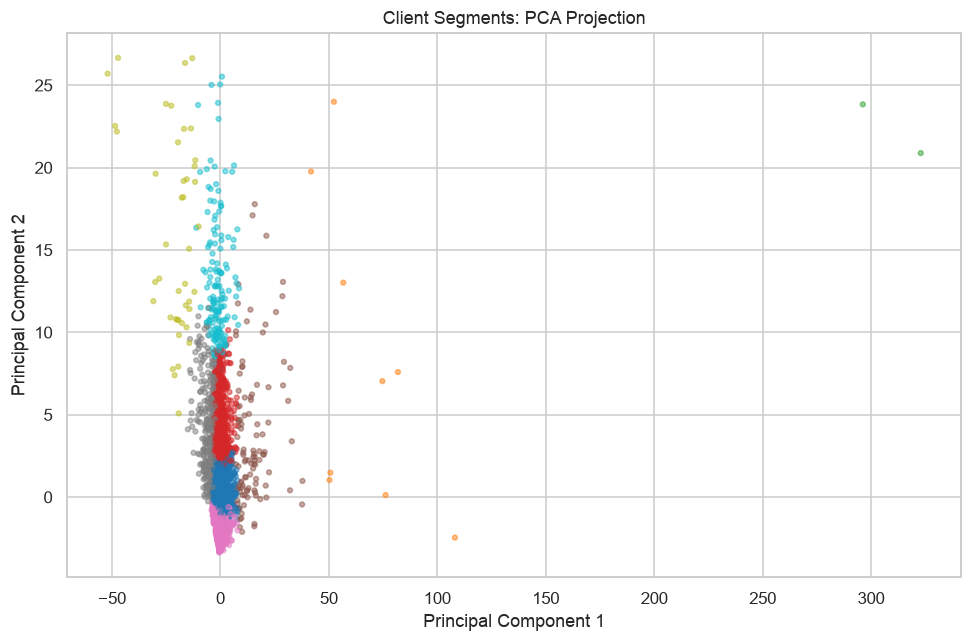

In [46]:

best_k = 9  # Replace with your chosen value

kmeans = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

# Project high-dimensional features to 2D
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X_scaled)

# Sample for plotting if the dataset is large
plot_df = pd.DataFrame({
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1],
    "Cluster": clusters
})

plot_df = plot_df.sample(
    min(10000, len(plot_df)), random_state=RANDOM_STATE
)

plt.figure(figsize=(9, 6))
plt.scatter(
    plot_df["PC1"], plot_df["PC2"],
    c=plot_df["Cluster"], cmap="tab10",
    alpha=0.5, s=10
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Client Segments: PCA Projection")
plt.tight_layout()
plt.show()


In [47]:
profile = df.copy()
profile["cluster"] = clusters

profile.groupby("cluster")[
    [
        "n_txn",
        #"inflow_sum",
        #"outflow_sum",
        "bal_mean",
        #"pct_neg_bal",
        "m0_arrearsamount",
    ]
].median().round(2)

,n_txn,bal_mean,m0_arrearsamount
cluster,,,
0,329.0000,671.1500,"1,256.0100"
1,341.5000,"125,912.8200","1,360.4000"
2,129.5000,"692,404.1100","3,477.6200"
3,406.0000,-88.1000,"3,372.2700"
4,374.0000,"26,243.8300",954.8800
5,185.0000,689.9200,439.0300
6,70.0000,"-13,571.1400","2,460.0200"
7,122.0000,"-52,254.8800","4,693.6500"
8,350.0000,"-3,986.7600","8,889.5500"


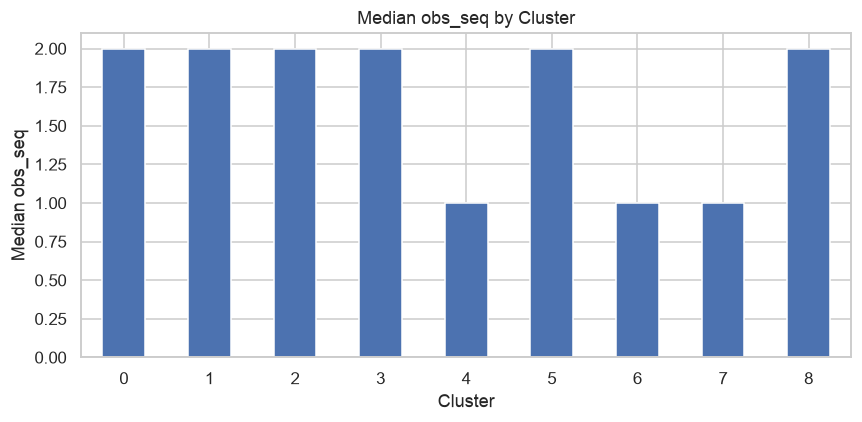

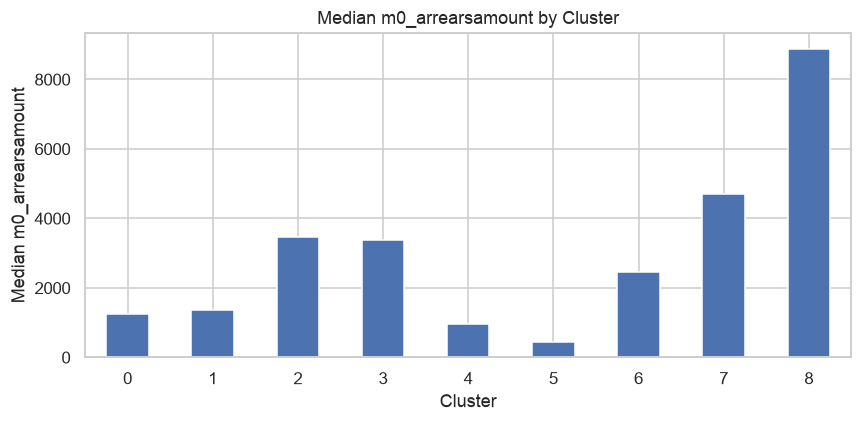

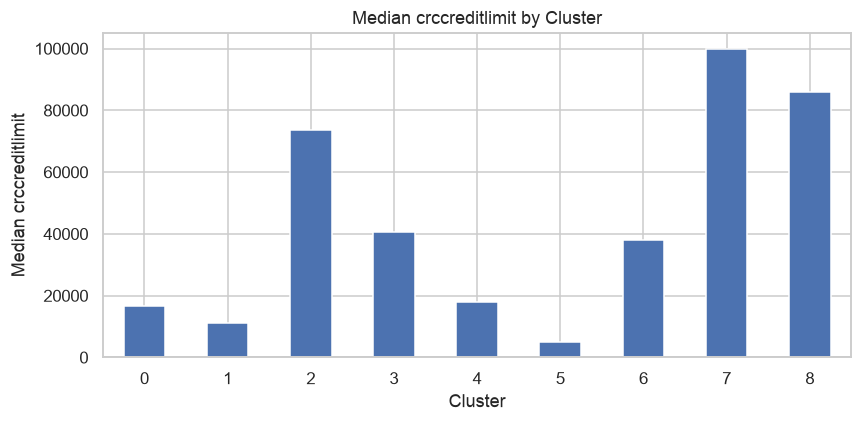

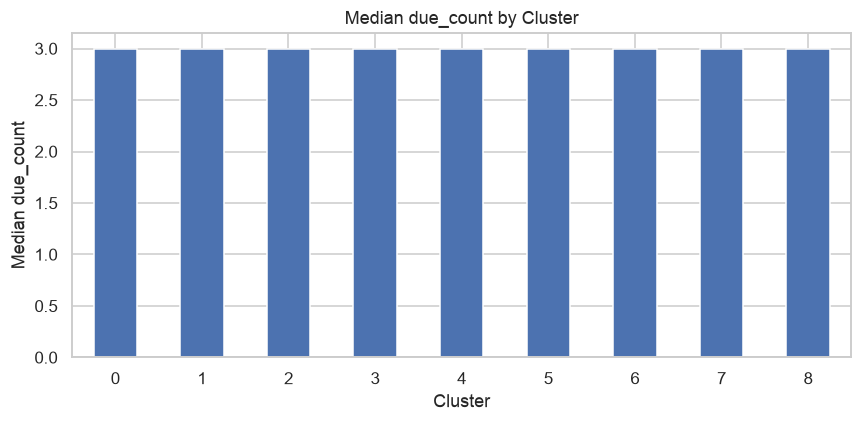

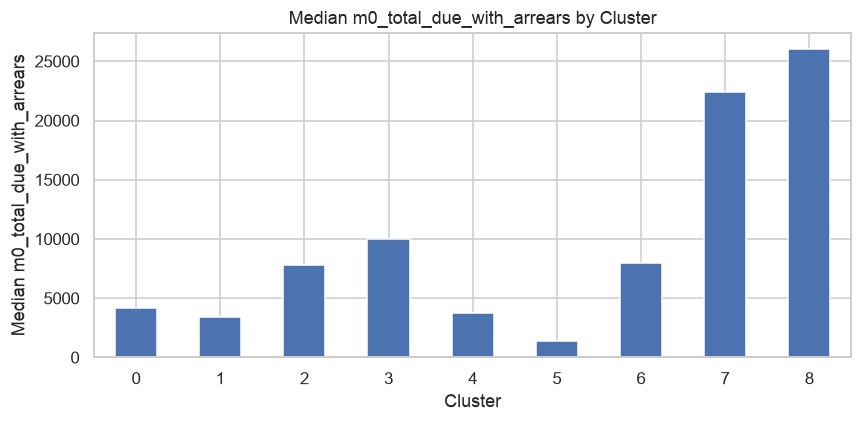

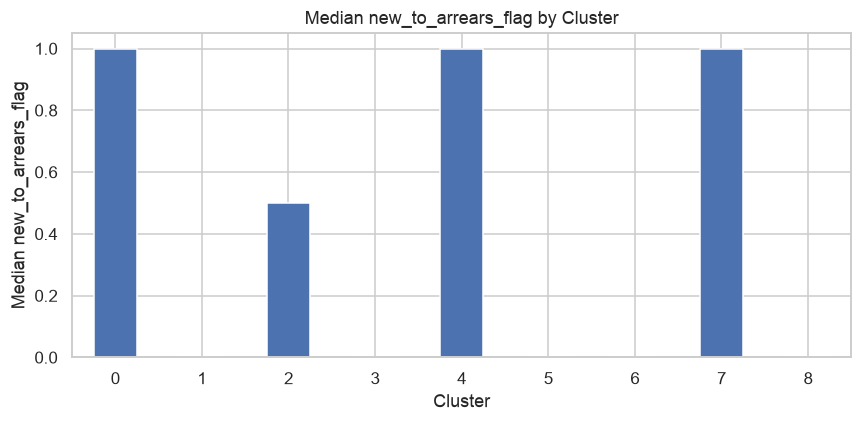

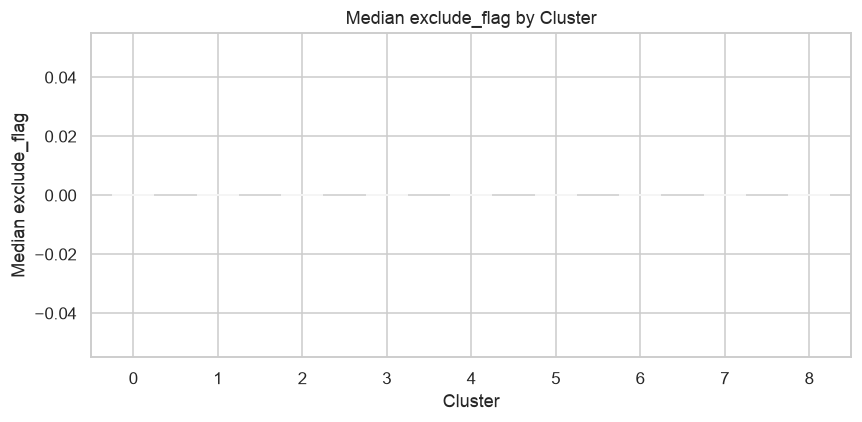

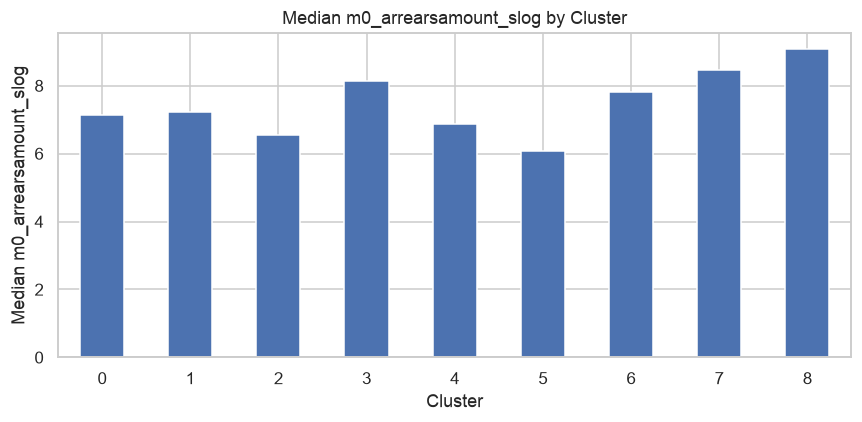

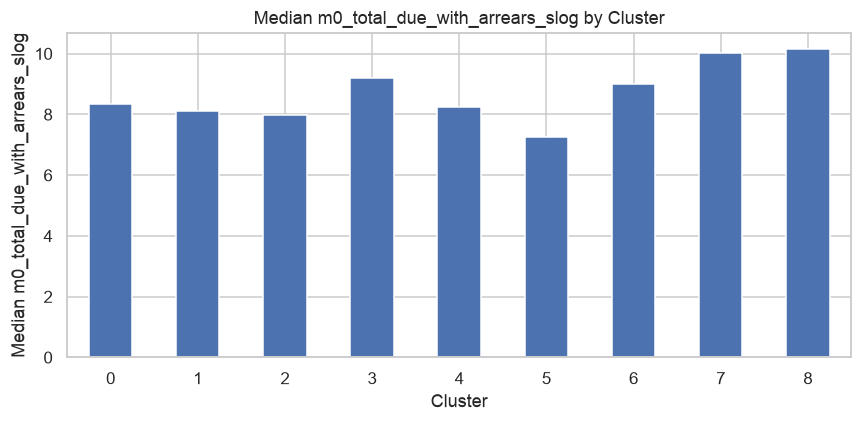

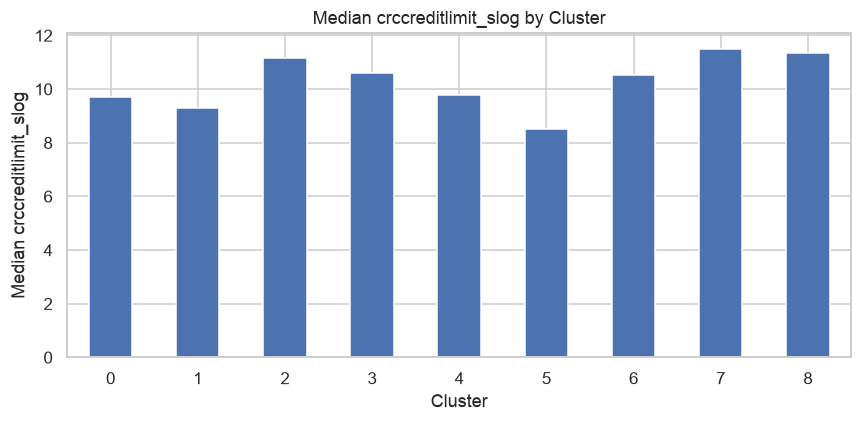

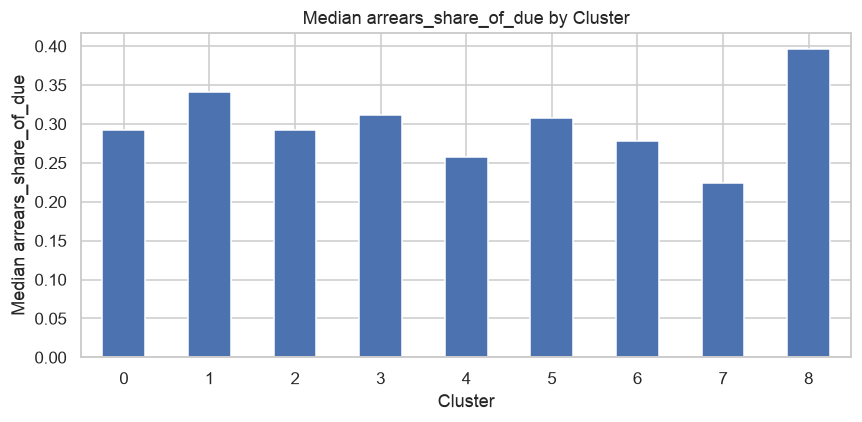

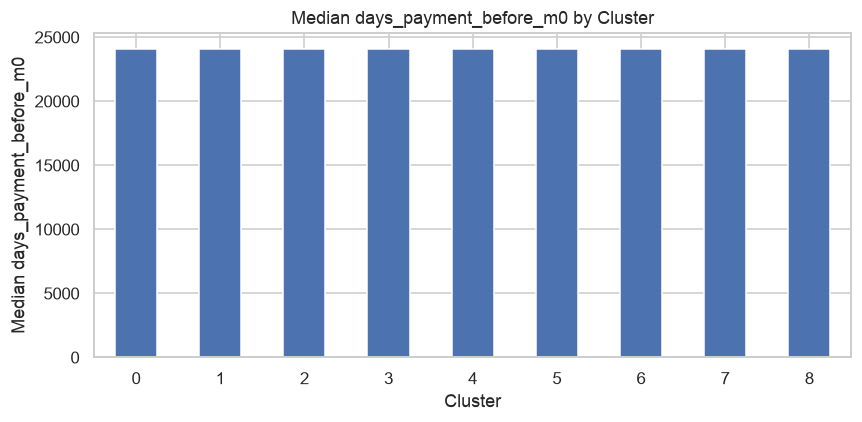

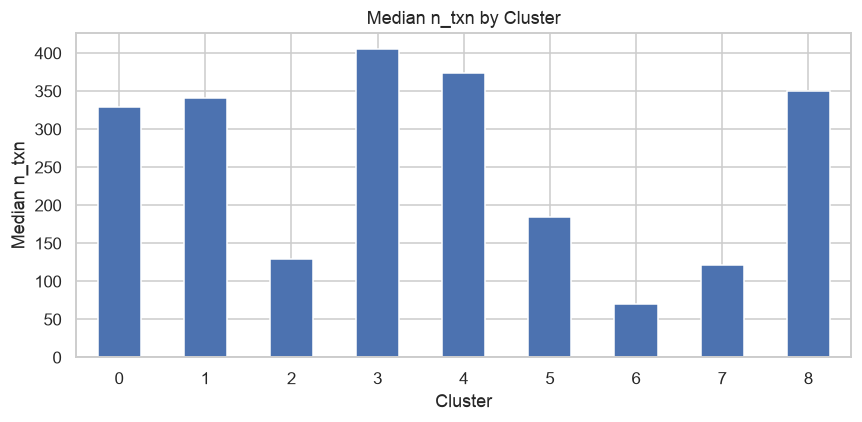

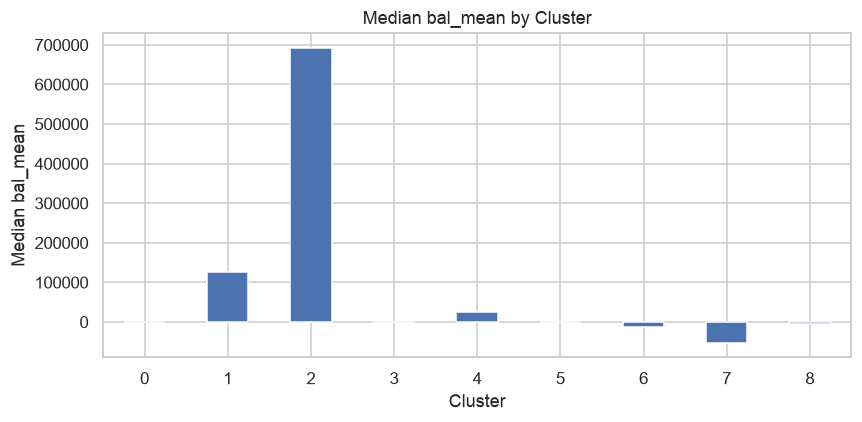

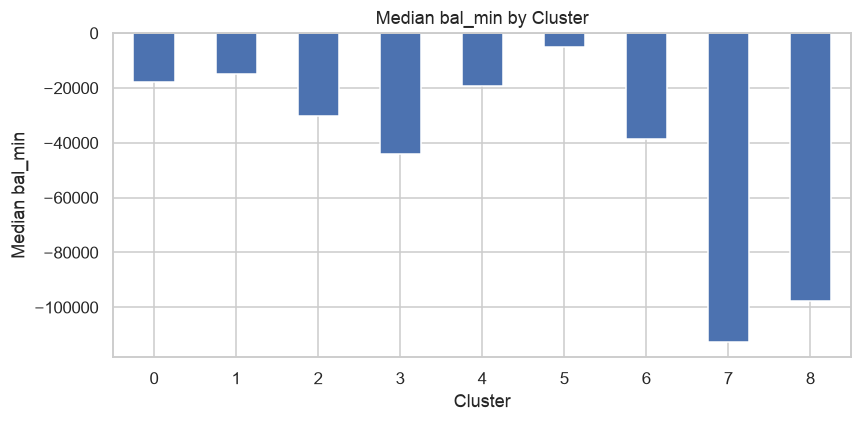

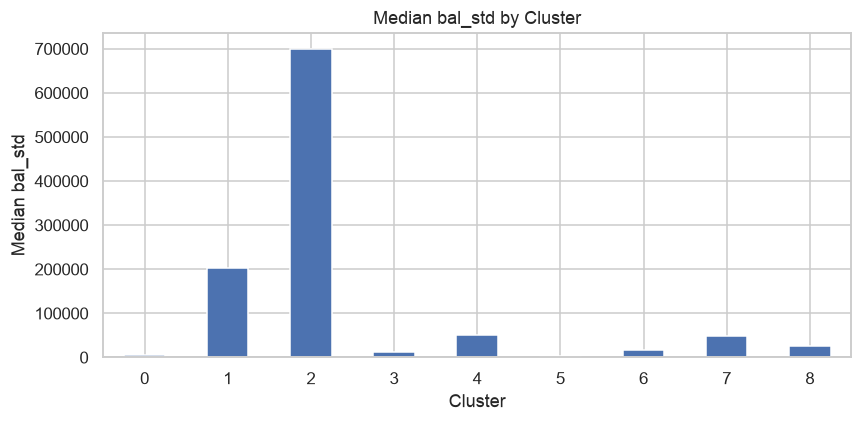

In [50]:
# Replace these names with your actual DataFrame and cluster column
feature_cols = X.select_dtypes(include="number").columns

# Calculate median feature values for each cluster
median_features = (
    X.assign(cluster=clusters)
     .groupby("cluster")[feature_cols]
     .median()
)

# Plot each feature separately, giving each its own scale
for feature in median_features.columns:
    ax = median_features[feature].plot(
        kind="bar",
        figsize=(8, 4),
        title=f"Median {feature} by Cluster"
    )

    ax.set_xlabel("Cluster")
    ax.set_ylabel(f"Median {feature}")
    ax.tick_params(axis="x", rotation=0)

    plt.tight_layout()
    plt.show()

In [49]:
profile.groupby("cluster").agg(
    clients=("cifwithcheckdigit", "nunique"),
    observations=("target_value", "size"),
    target_rate=("target_value", "mean"),
)

,clients,observations,target_rate
cluster,,,
0,1942,3506,0.4949
1,7,10,0.4000
2,2,2,0.0000
3,613,1030,0.5301
4,83,115,0.4957
5,2547,5289,0.5322
6,204,333,0.5405
7,28,43,0.1860
8,102,171,0.6316
